# ЛР-1. Аудит и подготовка данных информационной безопасности

**Вариант 3.** Фокус анализа: `timestamp, hour, is_weekend, device_type, os_family, browser_family, known_device`. Основная проверка — временное разделение по `timestamp`.

Данные: `data/auth_events_lab01.xlsx`.

In [16]:
import sys
import warnings
from pathlib import Path

import joblib                                          # сохранение обученного pipeline в artifacts/
import matplotlib.pyplot as plt                        # для графиков
import numpy as np
import pandas as pd
import seaborn as sns                                  # boxplot для распределений числовых признаков
import sklearn
from sklearn.compose import ColumnTransformer          # разные преобразования для числовых и категориальных столбцов
from sklearn.impute import SimpleImputer               # заполнение пропусков внутри pipeline
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit  # сравнение схем разделения
from sklearn.pipeline import Pipeline                  # общий конвейер preprocessing
from sklearn.preprocessing import OneHotEncoder, RobustScaler

RANDOM_STATE = 42                               
DATA_PATH = Path('data/auth_events_lab01.xlsx')

print(sys.version)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

3.14.7 (main, Sep  1 2026, 14:05:28) [Clang 22.1.3 ]
pandas: 3.0.6
scikit-learn: 1.9.1


## 1. Постановка задачи

##### **Прикладная задача ИБ.**
Оценить каждую попытку аутентификации пользователя и отнести её к нормальной (`is_suspicious=0`) или подозрительной (`is_suspicious=1`). Результат использует SOC-аналитик и средство аутентификации: пропустить вход, временно заблокировать учётную запись или создать инцидент.

##### **Объект анализа и гранулярность.**
Объект — одна попытка аутентификации. У одного `user_id` 4-23 события (всего 120 пользователей), и решение принимается на каждую попытку.


##### **Целевая переменная.**
`is_suspicious`: `1` — подозрительное событие, `0` — нормальное. Метка появилась после расследования, поэтому её название не считается доказательством корректности разметки.

##### **Происхождение и ограничения.**
Набор синтетический, период с 01.01.2026 по 31.03.2026, исходно 1430 строк и 23 столбца. Распределения атак, география, парк устройств и счётчики упрощены; есть артефакты генератора (коды 999 и 20000, идеальный зазор риска 68/78, часовые пики), поэтому выводы нельзя переносить в реальный SOC без пилота и мониторинга.

##### **Что есть X, что есть y.**
`y` - `is_suspicious` известна только после расследования. `X` — 16 признаков, доступных в момент попытки входа (10 числовых: `hour`, `is_weekend`, `failed_attempts_24h`, `login_velocity_1h`, `distance_from_usual_km`, `account_age_days`, `password_age_days`, `known_device`, `new_country`, `vpn_used`; 6 категориальных: `department`, `country`, `device_type`, `os_family`, `browser_family`, `auth_method`), а 6 полей исключены — `analyst_verdict` и `analyst_risk_score` как утечка метки, `event_id`, `source_ip`, `user_id` и сырой `timestamp` как идентификаторы и риск запоминания.

### Таблица признаков

Фактический тип — по загрузке pandas; ожидаемый — по смыслу столбца.

| Столбец | Смысл | Фактический тип | Ожидаемый тип | Допустимые значения | Момент доступности | Решение об использовании |
|---|---|---|---|---|---|---|
| event_id | технический идентификатор записи | str | string | уникален | в момент события | исключить (идентификатор) |
| timestamp | время попытки | str (смешанные форматы) | datetime | 2026-01-01…2026-03-31 | в момент события | в X не входит; парсится для временного разделения, 4 недостоверные строки удаляются |
| user_id | псевдоним учётной записи | str | category | usr_xxx (120 значений) | в момент события | исключить из X (идентификатор/группа) |
| department | подразделение | str + NaN/unknown | category | SOC/R&D/HR/Operations/IT/Sales/Finance | до события | оставить |
| source_ip | IP источника | str | string | 320 уникальных | в момент события | исключить (идентификатор) |
| country | страна по IP | str | category | 9 стран, ISO-2 | в момент события | оставить |
| device_type | тип устройства | str | category | mobile/tablet/laptop/desktop | в момент события | оставить (**фокус варианта 3**) |
| os_family | семейство ОС | str | category | Android/Windows/iOS/macOS/Linux | в момент события | оставить (**фокус**) |
| browser_family | семейство браузера | str + NaN/`-` | category | Chrome/Safari/Edge/Firefox | в момент события | оставить, `-` → NaN (**фокус**) |
| auth_method | способ аутентификации | str | category | password/push/otp/fido2 | в момент события | оставить |
| hour | час суток UTC | int64 | integer | 0–23 | в момент события | оставить числовым (**фокус**) |
| is_weekend | выходной день | int64 | binary | 0/1 | в момент события | оставить (**фокус**) |
| failed_attempts_24h | неуспешные попытки за 24 ч | int64 | integer | ≥ 0 | в момент события | оставить; `-1` и `999` → NaN |
| login_velocity_1h | попыток входа за час | int64 | integer | ≥ 1 | в момент события | оставить |
| distance_from_usual_km | расстояние от обычной геолокации | float64 | float | ≥ 0 | в момент события | оставить; `-25` → NaN; 20000 оставлено |
| account_age_days | возраст учётной записи, дни | int64 | integer | ≥ 0 | до события | оставить; `-7` → NaN |
| password_age_days | возраст пароля, дни | object (unknown) | integer | ≥ 0 | до события | unknown → NaN → число |
| known_device | устройство известно системе | int64 | binary | 0/1 | в момент события | оставить (**фокус**) |
| new_country | новая страна для пользователя | int64 | binary | 0/1 | в момент события | оставить |
| vpn_used | обнаружено использование VPN | int64 | binary | 0/1 | в момент события | оставить |
| analyst_verdict | итог ручной проверки | str | category | benign/confirmed_threat | **после расследования** | **исключить (прямая утечка)** |
| analyst_risk_score | оценка риска аналитика | int64 | integer | 0–100 | **после расследования** | **исключить (прямая утечка)** |
| is_suspicious | целевая метка | int64 | binary | 0/1 | после расследования | **y** |



## 2. Загрузка и первичная инвентаризация



In [17]:
df = pd.read_excel(DATA_PATH, sheet_name='Данные')

# Исходные размеры
N0, C0 = df.shape

# 1. Первые и последние строки
print('--- первые строки ---')
print(df.head(3).to_string())
print('\n--- последние строки ---')
print(df.tail(3).to_string())

# 2. Размер таблицы
print(f'\n--- размер таблицы ---')
print(f'{N0} строк × {C0} столбцов')

# 3. Названия столбцов
print('\n--- названия столбцов ---')
print(list(df.columns))

# 4. Типы данных
print('\n--- типы данных ---')
print(df.dtypes.to_string())

# 5. Объём памяти
print(f'\n--- объём памяти ---')
print(f'{df.memory_usage(deep=True).sum() / 1024:.1f} KiB')

# 6. Проверка: число строк соответствует числу объектов, целевой столбец присутствует ровно один раз
# Объект анализа — одна попытка аутентификации; одна строка = одно событие
print('\n--- проверки ---')
print('Одна строка = одна попытка аутентификации:',
      df.shape[0] == len(df))
print('Целевой столбец is_suspicious присутствует ровно 1 раз:',
      list(df.columns).count('is_suspicious') == 1)

# 7. Описательные статистики числовых признаков
print('\n--- описательные статистики числовых признаков ---')
print(df.describe(include=[np.number]).T.to_string())

# 8. Категориальные: число уникальных значений и наиболее частые категории
print('\n--- категориальные: число уникальных значений и наиболее частые категории ---')
for c in ['user_id', 'department', 'country', 'device_type', 'os_family',
          'browser_family', 'auth_method', 'analyst_verdict']:
    print(f'\n{c}: уникальных = {df[c].nunique(dropna=False)}')
    print(df[c].value_counts(dropna=False).head(5).to_string())

--- первые строки ---
     event_id            timestamp  user_id  department      source_ip country device_type os_family browser_family auth_method  hour  is_weekend  failed_attempts_24h  login_velocity_1h  distance_from_usual_km  account_age_days password_age_days  known_device  new_country  vpn_used analyst_verdict  analyst_risk_score  is_suspicious
0  evt_001370  2026-03-12 20:27:57  usr_046  Operations  203.0.113.178      SE      mobile   Android         Chrome    password    20           0                    0                  1                    39.4               871               229             0            0         0          benign                  65              0
1  evt_000493  2026-01-06 00:17:20  usr_068       Sales  203.0.113.132      RU      mobile   Android         Chrome    password     0           0                    0                  5                    16.9              2383                11             1            0         0          benign            

/Users/assweg/Desktop/NSTU/7sem/Системы искусственного интелекта/ЛР1/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## 3. Проверка типов и допустимых значений

1. Ищем условные обозначения пропусков (`?`, `-`, `unknown`, пустая строка) и разный регистр одного значения;
2. Парсим `timestamp` в два прохода: стандартные форматы, затем явный `DD.MM.YYYY` с проверкой согласованности с полем `hour`;
3. Приводим `password_age_days` к числу, переводя строку `unknown` в `NaN`;
4. Раскрываем `unknown` и `-` в `NaN`, чтобы они не стали отдельными категориями;
5. Переводим в `NaN` нарушения ограничений: `-1`, `999`, `-25`, `-7`;
6. Проверяем диапазоны и согласованность: `hour`, `is_weekend`, бинарные признаки, ISO-2 у `country`, совместимость устройства и ОС.

In [18]:
# Список ожидаемых типов 
expected = {
    'event_id': 'string', 'timestamp': 'datetime', 'user_id': 'category',
    'department': 'category', 'source_ip': 'string', 'country': 'category',
    'device_type': 'category', 'os_family': 'category', 'browser_family': 'category',
    'auth_method': 'category', 'hour': 'integer', 'is_weekend': 'binary',
    'failed_attempts_24h': 'integer', 'login_velocity_1h': 'integer',
    'distance_from_usual_km': 'float', 'account_age_days': 'integer',
    'password_age_days': 'integer', 'known_device': 'binary', 'new_country': 'binary',
    'vpn_used': 'binary', 'analyst_verdict': 'category',
    'analyst_risk_score': 'integer', 'is_suspicious': 'binary',
}
print('--- 3.1. Сопоставление фактического и ожидаемого типа ---')
for c, exp in expected.items():
    fact = str(df[c].dtype)
    ok = ((exp in ('integer', 'binary') and 'int' in fact) or
          (exp == 'float' and 'float' in fact) or
          (exp == 'datetime' and 'datetime' in fact) or
          (exp in ('string', 'category') and fact in ('str', 'object', 'category')))
    print(f"  {c}: ожидание={exp}, факт={fact} — {'OK' if ok else 'Расхождение'}")

# Первый проход — стандартные форматы ISO; всё, что не распознано, печатается построчно.
ts_first = pd.to_datetime(df['timestamp'], errors='coerce')
print(f"\n--- 3.2. timestamp ---")
print(f"Не распознано с первого прохода: {int(ts_first.isna().sum())} строк "
      f"({ts_first.isna().mean():.2%})")
print(df.loc[ts_first.isna(), ['event_id', 'timestamp']].to_string(index=False))

# Второй проход — явный формат DD.MM.YYYY (чтобы не удалять строку с другим форматом даты).
ts_alt = pd.to_datetime(df.loc[ts_first.isna(), 'timestamp'],
                        format='%d.%m.%Y %H:%M', errors='coerce')
print(f"\nВторой проход (DD.MM.YYYY) распознал ещё {int(ts_alt.notna().sum())} строку.")
if ts_alt.notna().any():
    recovered = ts_alt.dropna()
    cand = df.loc[recovered.index, ['event_id', 'timestamp', 'hour']].copy()
    cand['час из строки'] = recovered.dt.hour.values
    print(cand.to_string(index=False))
    # Сверка восстановленного часа с полем hour: расхождение означает, что время испорчено целиком.
    print('Согласовано с hour:', bool((cand['час из строки'] == cand['hour']).all()),
          '— восстанавливать нельзя.')

df['timestamp_parsed'] = ts_first
print(f'Итого недостоверных timestamp: {int(ts_first.isna().sum())} строк — удаляются в разделе 9.')

# 3.3. Числовые значения, загруженные как строки: password_age_days
n_pwd_unknown = int((df['password_age_days'].astype(str) == 'unknown').sum())
df['password_age_days'] = pd.to_numeric(
    df['password_age_days'].astype(str).str.replace('unknown', '', regex=False).replace('', np.nan),
    errors='coerce')
print(f"\n--- 3.3. password_age_days ---")
print(f"'unknown' -> NaN: {n_pwd_unknown} строк, тип -> {df['password_age_days'].dtype}")

# 3.4. Ошибочные варианты написания категорий: '-' и 'unknown' — это пропуски, не категории
n_dash = int((df['browser_family'] == '-').sum())
n_dep_unknown = int((df['department'] == 'unknown').sum())
df['browser_family'] = df['browser_family'].replace('-', np.nan)
df['department'] = df['department'].replace('unknown', np.nan)
print(f"\n--- 3.4. Условные маркеры -> NaN ---")
print(f"browser_family '-': {n_dash}; department 'unknown': {n_dep_unknown}")

# 3.5. Предметные ограничения: формулировка, примеры нарушающих строк, исправление
# Ограничения: failed_attempts_24h >= 0, distance_from_usual_km >= 0, account_age_days >= 0.
print("\n--- 3.5. Нарушения предметных ограничений ---")
viol_mask = {
    'failed_attempts_24h = -1': df['failed_attempts_24h'] == -1,
    'failed_attempts_24h = 999': df['failed_attempts_24h'] == 999,
    'distance_from_usual_km = -25': df['distance_from_usual_km'] == -25,
    'account_age_days = -7': df['account_age_days'] == -7,
}
for name, mask in viol_mask.items():
    n = int(mask.sum())
    print(f"\n{name}: {n} строк")
    if n:
        print(df.loc[mask, ['event_id'] + [name.split(' = ')[0]]].to_string(index=False))

# Исправление: код/ошибка -> NaN, значение закроется медианой внутри pipeline (раздел 10).
df.loc[df['failed_attempts_24h'].isin([-1, 999]), 'failed_attempts_24h'] = np.nan
df.loc[df['distance_from_usual_km'] == -25, 'distance_from_usual_km'] = np.nan
df.loc[df['account_age_days'] == -7, 'account_age_days'] = np.nan

# 3.6. Проверка допустимых значений и согласованности признаков после исправлений
ts_ok = df['timestamp_parsed'].notna()
mobile = df['device_type'].isin(['mobile', 'tablet'])
checks = {
    'hour вне диапазона 0..23': int((~df['hour'].between(0, 23)).sum()),
    'hour не совпадает с timestamp': int((df.loc[ts_ok, 'hour'] != df.loc[ts_ok, 'timestamp_parsed'].dt.hour).sum()),
    'is_weekend не совпадает с timestamp': int((df.loc[ts_ok, 'is_weekend'] !=
                                               (df.loc[ts_ok, 'timestamp_parsed'].dt.dayofweek >= 5).astype(int)).sum()),
    'бинарные признаки вне {0,1}': int(sum((~df[c].dropna().isin([0, 1])).sum()
                                           for c in ['is_weekend', 'known_device', 'new_country', 'vpn_used', 'is_suspicious'])),
    'country вне формата ISO-2': int((~df['country'].dropna().str.fullmatch(r'[A-Z]{2}')).sum()),
    'несовместимая связка device_type и os_family': int(((mobile & ~df['os_family'].isin(['Android', 'iOS'])) |
                                                          (~mobile & ~df['os_family'].isin(['Windows', 'Linux', 'macOS']))).sum()),
    'отрицательные счётчики после чистки': int((df[['failed_attempts_24h', 'login_velocity_1h', 'account_age_days',
                                                    'password_age_days', 'distance_from_usual_km']] < 0).sum().sum()),
}
print('\n--- 3.6. Проверка допустимых значений ---')
for key, val in checks.items():
    print(f'  {key}: {val}')
assert all(v == 0 for v in checks.values()), 'найдены нарушения допустимых значений'
print('Расхождений нет: hour и is_weekend согласованы с timestamp, связки устройств корректны.')

--- 3.1. Сопоставление фактического и ожидаемого типа ---
  event_id: ожидание=string, факт=str — OK
  timestamp: ожидание=datetime, факт=str — Расхождение
  user_id: ожидание=category, факт=str — OK
  department: ожидание=category, факт=str — OK
  source_ip: ожидание=string, факт=str — OK
  country: ожидание=category, факт=str — OK
  device_type: ожидание=category, факт=str — OK
  os_family: ожидание=category, факт=str — OK
  browser_family: ожидание=category, факт=str — OK
  auth_method: ожидание=category, факт=str — OK
  hour: ожидание=integer, факт=int64 — OK
  is_weekend: ожидание=binary, факт=int64 — OK
  failed_attempts_24h: ожидание=integer, факт=int64 — OK
  login_velocity_1h: ожидание=integer, факт=int64 — OK
  distance_from_usual_km: ожидание=float, факт=float64 — OK
  account_age_days: ожидание=integer, факт=int64 — OK
  password_age_days: ожидание=integer, факт=object — Расхождение
  known_device: ожидание=binary, факт=int64 — OK
  new_country: ожидание=binary, факт=int64 

## 4. Анализ пропусков

1. Убедимся, что в целевой переменной пропусков нет, и не заполняем её;
2. Считаем число и долю пропусков по столбцам, печатаем только столбцы с пропусками по убыванию доли;
3. Считаем, сколько строк затронуто хотя бы одним пропуском;
4. Фиксируем решение по каждому признаку: мода для категориальных, медиана для числовых, заполнение внутри pipeline.

In [19]:
print('Пропуски в целевой переменной y:', int(df['is_suspicious'].isna().sum()))

# Вывод только столбцов с пропусками, отсортированные по убыванию доли
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print('\nСтолбцы с пропусками:')
print(pd.DataFrame({'пропусков': miss, 'доля': (miss / len(df)).round(4)}).to_string())
n_any = int(df.isna().any(axis=1).sum())   # сколько строк затронуто хотя бы одним пропуском
print(f'\nСтрок хотя бы с одним пропуском: {n_any} ({n_any / len(df):.2%})')

# Проверка, не скрываются ли пропуски под условными обозначениями
markers = ['?', '-', '--', 'unknown', 'n/a', 'null', 'none', 'nan']
leftovers = {}
for c in df.columns:
    v = df[c].dropna().astype(str)
    for mk in markers:
        n = int((v.str.strip().str.lower() == mk).sum())
        if n:
            leftovers[f'{c} = {mk!r}'] = n
    if int((v == '').sum()):
        leftovers[f'{c}: пустая строка'] = int((v == '').sum())
    if int((v != v.str.strip()).sum()):
        leftovers[f'{c}: пробелы по краям'] = int((v != v.str.strip()).sum())
print('Скрытые обозначения пропусков, оставшиеся после раздела 3:', leftovers or 'нет')

# Ноль проверяем по смыслу признака: счётчик неуспешных попыток и расстояние могут быть нулевыми, а интенсивность входа нет
zero_check = {
    'failed_attempts_24h = 0 (допустимо)': int((df['failed_attempts_24h'] == 0).sum()),
    'distance_from_usual_km = 0 (допустимо)': int((df['distance_from_usual_km'] == 0).sum()),
    'login_velocity_1h = 0 (невозможно, был бы пропуск)': int((df['login_velocity_1h'] == 0).sum()),
    'account_age_days = 0 (учётка создана сегодня)': int((df['account_age_days'] == 0).sum()),
}
print('\nПроверка нулей по смыслу признака:', zero_check)


Пропуски в целевой переменной y: 0

Столбцы с пропусками:
                        пропусков    доля
browser_family                 40  0.0280
distance_from_usual_km         36  0.0252
department                     22  0.0154
password_age_days               9  0.0063
failed_attempts_24h             5  0.0035
timestamp_parsed                4  0.0028
account_age_days                3  0.0021

Строк хотя бы с одним пропуском: 119 (8.32%)
Скрытые обозначения пропусков, оставшиеся после раздела 3: нет

Проверка нулей по смыслу признака: {'failed_attempts_24h = 0 (допустимо)': 890, 'distance_from_usual_km = 0 (допустимо)': 1, 'login_velocity_1h = 0 (невозможно, был бы пропуск)': 0, 'account_age_days = 0 (учётка создана сегодня)': 0}


**Обоснование решений с позиции смысла признака.**

Столбцы `department` и `browser_family` — категориальные и содержательные: подразделение и браузер влияют на профиль риска пользователя, поэтому удалять их нельзя, а пропуски логично закрыть модой — самым частым значением, которое не создаёт новых фиктивных категорий. Числовые признаки `distance_from_usual_km`, `password_age_days`, `failed_attempts_24h`, `account_age_days` — ключевые сигналы аномалии: расстояние от обычной геолокации и счётчик неудачных попыток напрямую указывают на возможную атаку, возраст учётной записи и пароля описывают профиль пользователя, поэтому эти столбцы сохраняются, а пропуски в них закрываются медианой — она устойчива к выбросам и не смещает распределение. Столбец `timestamp_parsed` не является признаком: это производная от времени, используемая как ключ временного разделения, поэтому строки без достоверного времени удаляются, а не заполняются. Ни один столбец не удаляется, потому что все признаки содержательны, а доли пропусков малы; удаление строк также не применяется — потеря информации не оправдана. Все заполнения выполняются внутри pipeline и обучаются только на `X_train`, поэтому статистики test в преобразование не попадают.

**О целевой переменной и обучении с учителем.**

Целевую переменную `is_suspicious` автоматически заполнять нельзя: она появляется только после расследования инцидента и является ответом, который модель должна предсказывать. Подставлять её модой, нулём или любым другим значением недопустимо — это исказит разметку и сделает обучение бессмысленным. В наборе пропусков в `y` нет, поэтому отделять строки без надёжной метки не требуется. Если бы такие строки нашлись, использовать их в обучении с учителем нельзя: модель не знает правильного ответа, а подставленная автоматически метка не отражает реальность. Такие строки следовало бы либо исключить из обучения, либо разметить вручную до начала эксперимента.

## 5. Поиск дубликатов и зависимых объектов

1. Считаем полные дубликаты строк и показываем несколько примеров;
2. Отдельно проверяем повторы `event_id`: полные копии это или коллизия идентификатора;
3. Удаляем полные копии и сохраняем число удалённых строк;
4. Считаем события на одного пользователя (min, медиана, max) и число пользователей с событиями обоих классов — это оценка зависимости объектов.

In [20]:
# Полные дубликаты строк
n_full_dup = int(df.duplicated().sum())
print(f'Полных дубликатов строк: {n_full_dup} ({n_full_dup / len(df):.2%})')
# Примеры дубликатов. keep=False выводит все строки, у которых есть полный дубликат
print(df[df.duplicated(keep=False)].sort_values('event_id')
      [['event_id', 'timestamp', 'user_id', 'device_type', 'is_suspicious']].head(6).to_string(index=False))

# Повторы event_id: проверяем, что это те же полные дубликаты, а не коллизия идентификатора
dup_ids = df[df.duplicated('event_id', keep=False)]
print(f"\nПовторов event_id: {int(df.duplicated('event_id').sum())}, групп: {dup_ids['event_id'].nunique()}; "
      f"все повторы — полные копии строк: {all(sub.drop_duplicates().shape[0] == 1 for _, sub in dup_ids.groupby('event_id'))}")

# Удаление полных дубликатов
df = df.drop_duplicates().reset_index(drop=True)
print(f'После удаления полных дубликатов: {df.shape[0]} строк (удалено {n_full_dup})')

# Сколько событий приходится на одного пользователя
upc = df['user_id'].value_counts()
print(f"\nПользователей: {df['user_id'].nunique()}, событий на пользователя: "
      f"min={upc.min()}, медиана={upc.median()}, max={upc.max()}")
      

Полных дубликатов строк: 18 (1.26%)
  event_id           timestamp user_id device_type  is_suspicious
evt_000020 2026-01-02 02:54:41 usr_089      mobile              0
evt_000020 2026-01-02 02:54:41 usr_089      mobile              0
evt_000107 2026-01-08 01:00:54 usr_117      laptop              0
evt_000107 2026-01-08 01:00:54 usr_117      laptop              0
evt_000115 2026-01-25 14:51:47 usr_009      mobile              0
evt_000115 2026-01-25 14:51:47 usr_009      mobile              0

Повторов event_id: 18, групп: 18; все повторы — полные копии строк: True
После удаления полных дубликатов: 1412 строк (удалено 18)

Пользователей: 120, событий на пользователя: min=4, медиана=12.0, max=23


Связанные события одного пользователя похожи между собой (устройство, география, время), поэтому при попадании и в train, и в test модель узнаёт пользователя, а не учится ловить атаку, метрики на тесте оказываются завышенными относительно реальной работы на новых людях.

## 6. Выбросы и подозрительные значения

1. Считаем квантили (50, 90, 95, 99) по четырём числовым признакам;
2. Помечаем выбросы методом межквартильного размаха и печатаем границы и доли;
3. Строим boxplot по трём признакам;
4. Формулируем правило обработки для каждого признака — ничего не удаляем;
5. Смотрим распределение по устройствам и по времени: это фокус варианта 3.

                         count         mean          std   min     50%      90%       95%       99%      max
failed_attempts_24h     1407.0     0.501777     0.770059   0.0     0.0     1.00     2.000     3.000      5.0
distance_from_usual_km  1376.0   377.018968  1863.756256   0.0    31.2    85.95   142.175  9983.725  20000.0
account_age_days        1409.0  1642.977289   918.553118  62.0  1660.0  2973.60  3159.600  3232.920   3266.0
login_velocity_1h       1412.0     3.190510     2.214531   1.0     3.0     5.00     7.000    12.000     18.0

Отметки методом межквартильного размаха (для описания, удаление не применяется):
  failed_attempts_24h: 32 (2.27%), границы [-1.50, 2.50]
  distance_from_usual_km: 81 (5.74%), границы [-44.90, 116.70]
  account_age_days: 0 (0.00%), границы [-1431.50, 4644.50]
  login_velocity_1h: 57 (4.04%), границы [-1.00, 7.00]


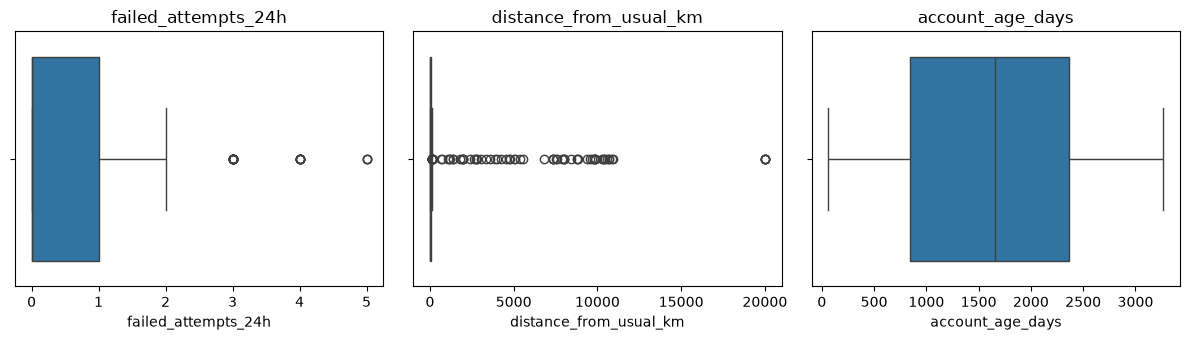


Сколько раз каждая категория встречается в датасете:
device_type
mobile     484
tablet     332
laptop     322
desktop    274

Доля suspicious по device_type:
is_suspicious      0      1
device_type                
desktop        0.880  0.120
laptop         0.922  0.078
mobile         0.905  0.095
tablet         0.934  0.066


           hour  is_weekend  known_device
mean  11.695467    0.279745       0.91289
min    0.000000    0.000000       0.00000
max   23.000000    1.000000       1.00000


In [21]:
# Четыре числовых признака
num_audit = ['failed_attempts_24h', 'distance_from_usual_km', 'account_age_days', 'login_velocity_1h']

# Вывод статистик (count, mean, std, min и квантили 50/90/95/99%, max) по признакам
print(df[num_audit].describe(percentiles=[.5, .9, .95, .99]).T.to_string())

# Межквартильный размах (IQR): границы Тьюки Q1-1.5·IQR и Q3+1.5·IQR. Считаем количество и долю отметок
print('\nОтметки методом межквартильного размаха (для описания, удаление не применяется):')
for c in num_audit:
    s = df[c].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr   # классические границы выбросов
    n = int(((s < lo) | (s > hi)).sum())
    print(f'  {c}: {n} ({n / len(df):.2%}), границы [{lo:.2f}, {hi:.2f}]')

# Boxplot по трём признакам: форма распределения, медиана и крайние значения
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, ['failed_attempts_24h', 'distance_from_usual_km', 'account_age_days']):
    sns.boxplot(x=df[c].dropna(), ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# Сравниваем распределение по устройствам и по часам
print('\nСколько раз каждая категория встречается в датасете:')
print(df['device_type'].value_counts().to_string())
# C какого устройства чаще происходят атаки
print('\nДоля suspicious по device_type:')
print(pd.crosstab(df['device_type'], df['is_suspicious'], normalize='index').round(3).to_string())
# С какого часа чаще происходят атаки
print('\n')
print(df[['hour', 'is_weekend', 'known_device']].describe().loc[['mean', 'min', 'max']].to_string())

**Правила обработки выбросов.**

Значения-коды (`999` в `failed_attempts_24h`, `-1`, `-25`, `-7`) уже переведены в `NaN` и будут закрыты медианой внутри pipeline. Осмысленные редкие значения — `distance_from_usual_km = 20000` и хвост 3–5 неудачных попыток оставлены как возможные атаки. Обрезка значений не применяется, поэтому пороги по train не подбираются.

## 7. Дисбаланс целевой переменной

1. Считаем абсолютное число и долю объектов каждого класса;
2. Строим столбчатую диаграмму с подписями классов и числовыми значениями;
3. Определяем редкий класс и объясняем, почему accuracy здесь недостаточна; ресемплинг не применяем.

Абсолютное число объектов каждого класса:
is_suspicious
0    1286
1     126

Доля редкого класса 1 (suspicious): 0.089 (126 из 1412)


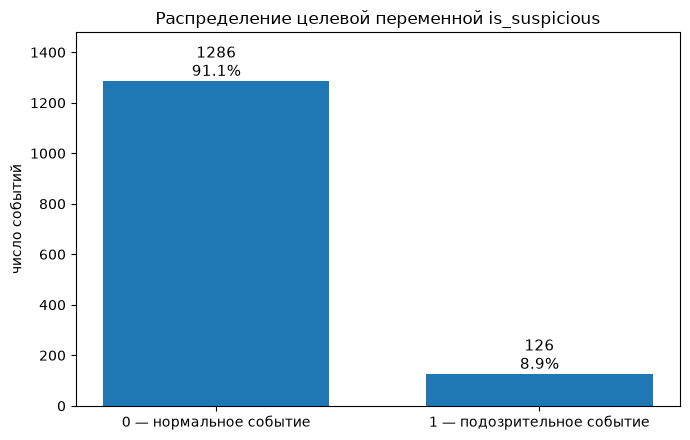

In [ ]:
# Абсолютное число объектов каждого класса и доля редкого класса
vc = df['is_suspicious'].value_counts().sort_index()
print('Абсолютное число объектов каждого класса:')
print(vc.to_string())
print(f'\nДоля редкого класса 1 (suspicious): {vc[1] / len(df):.3f} ({vc[1]} из {len(df)})')

# Столбчатая диаграмма распределения целевой переменной
fig, ax = plt.subplots(figsize=(7, 4.5))  # 1. Сделали график чуть шире и выше

# Параметр width=0.3 делает столбцы тоньше, тем самым раздвигая их
bars = ax.bar(['0 — нормальное событие', '1 — подозрительное событие'], [vc[0], vc[1]], width=0.7)

ax.set_title('Распределение целевой переменной is_suspicious')
ax.set_ylabel('число событий')

ax.set_ylim(0, max(vc) * 1.15)

# Вывод числа и доли над каждым столбцом
for b, v in zip(bars, [vc[0], vc[1]]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{v}\n{v / len(df):.1%}',
            ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

**Вывод по дисбалансу.**

Распределение правдоподобно для логов аутентификации — атаки редкие: класс 1 составляет около 9%. Поэтому accuracy недостаточна: константный прогноз «всегда 0» даёт примерно 91% при нулевом обнаружении атак, и оценивать модель нужно через precision, recall и PR-AUC. Ресемплинг (oversampling, undersampling, SMOTE) на этом этапе не применяется, он допустим только после разделения и только внутри train.

## 8. Поиск потенциальной утечки данных

1. Проверяем `analyst_verdict` на прямое совпадение с меткой через кросс-таблицу;
2. Смотрим распределение `analyst_risk_score` по классам и ищем зазор между ними;
3. Проверяем сильные, но легитимные признаки: `known_device`, `new_country`, `vpn_used`;
4. Оцениваем идентификаторы и время: сколько уникальных значений при каком числе строк;
5. Подтверждаем, что полных дубликатов после чистки не осталось.

Правило: признак должен быть известен в момент попытки аутентификации, когда средство защиты принимает решение. Всё, что появляется после расследования или почти прямо кодирует метку, — утечка. Вывод подтверждается количественно, без обучения будущей модели.

In [23]:
# Проверка "известно ли в момент входа" по всем столбцам датасета
known_at_login = {
    'event_id': True, 'timestamp': True, 'user_id': True, 'department': True,
    'source_ip': True, 'country': True, 'device_type': True, 'os_family': True,
    'browser_family': True, 'auth_method': True, 'hour': True, 'is_weekend': True,
    'failed_attempts_24h': True, 'login_velocity_1h': True,
    'distance_from_usual_km': True, 'account_age_days': True,
    'password_age_days': True, 'known_device': True, 'new_country': True,
    'vpn_used': True, 'analyst_verdict': False, 'analyst_risk_score': False,
    'is_suspicious': False,
}
print('Столбцы, НЕ известные в момент входа:', [c for c, ok in known_at_login.items() if not ok])

# Прямая утечка: analyst_verdict
print('\n--- analyst_verdict против целевой метки ---')
print(pd.crosstab(df['analyst_verdict'], df['is_suspicious']).to_string())

# Вторая прямая утечка: analyst_risk_score
print('\n--- analyst_risk_score по классам ---')
print(df.groupby('is_suspicious')['analyst_risk_score'].describe().to_string())
print(f"\nmax(score|y=0) = {df.loc[df.is_suspicious == 0, 'analyst_risk_score'].max()}, "
      f"min(score|y=1) = {df.loc[df.is_suspicious == 1, 'analyst_risk_score'].min()} ")

# Сильные, но легитимные признаки известны в момент входа, поэтому остаются в X
print('\n--- легитимные, но сильные признаки ---')
for c in ['known_device', 'new_country', 'vpn_used']:
    print(f'\n{c}:')
    print(pd.crosstab(df[c], df['is_suspicious'], normalize='index').round(3).to_string())

# Идентификаторы и время
print('\n--- идентификаторы и время ---')
for c in ['event_id', 'source_ip', 'user_id']:
    print(f'  {c}: {df[c].nunique()} уникальных значений на {len(df)} строк')
print(f"  timestamp: {df['timestamp_parsed'].min()} — {df['timestamp_parsed'].max()} (сырой признак — запоминание календаря)")

# Контрольная проверка: после удаления копий полных дубликатов не осталось, значит они не разойдутся по train и test
print('Полных дубликатов после чистки:', int(df.duplicated().sum()))

Столбцы, НЕ известные в момент входа: ['analyst_verdict', 'analyst_risk_score', 'is_suspicious']

--- analyst_verdict против целевой метки ---
is_suspicious        0    1
analyst_verdict            
benign            1286    0
confirmed_threat     0  126

--- analyst_risk_score по классам ---
                count       mean        std   min   25%   50%    75%   max
is_suspicious                                                             
0              1286.0  36.048212  19.548105   3.0  19.0  36.0  53.75  68.0
1               126.0  88.325397   6.658323  78.0  82.0  88.5  94.00  99.0

max(score|y=0) = 68, min(score|y=1) = 78 

--- легитимные, но сильные признаки ---

known_device:
is_suspicious      0      1
known_device               
0              0.585  0.415
1              0.942  0.058

new_country:
is_suspicious      0      1
new_country                
0              0.950  0.050
1              0.065  0.935

vpn_used:
is_suspicious      0      1
vpn_used                   
0 

### Реестр подозрительных полей

| Поле | Момент появления | Тип риска | Решение | Обоснование |
|---|---|---|---|---|
| analyst_verdict | после расследования | прямая утечка (benign ↔ 0, confirmed_threat ↔ 1) | исключить | буквально кодирует целевую метку |
| analyst_risk_score | после расследования | почти прямая утечка (y=0: 3–68, y=1: 78–99) | исключить | недоступен в момент решения, даёт ложное качество |
| event_id | в момент события | идентификатор, запоминание | исключить | технический id; 18 полных копий показали риск дублей |
| source_ip | в момент события | идентификатор (320 значений) | исключить | модель запоминает адрес вместо закономерности |
| user_id | в момент события | идентификатор, группа (4–23 события) | исключить из X | запоминание учётной записи; события попадают в train и test |
| timestamp (сырой) | в момент события | метка времени, запоминание | исключить как признак, использовать для сортировки при разделении | иначе модель выучит календарь; час и выходной есть в hour, is_weekend |
| new_country, known_device, vpn_used | в момент события | сильный, но легитимный сигнал | оставить | доступны в момент решения: new_country=1 → 93.5% suspicious |

## 9. Выбор и выполнение разделения

1. Отделяем `y` от `X` и исключаем признаки утечки, идентификаторы и сырое время;
2. Удаляем строки без достоверного времени — их нельзя поставить на временную ось;
3. Строим стратифицированную случайную схему и считаем пересечение пользователей train и test;
4. Строим групповую схему по `user_id` и доказываем, что пересечение групп пусто;
5. Строим основную временную схему 80/20, проверяем хронологию и сравниваем доли классов в train и test.

`X` и `y` разделяются до любых обучаемых преобразований; признаки утечки исключены заранее. Сравниваются три схемы: стратифицированная случайная (проверяет i.i.d.), групповая по `user_id` (проверяет обобщение на новых пользователей) и временная по `timestamp` (проверяет работу «прошлое → будущее»). Основная схема для варианта 3 — временная: фокус варианта — устройство и время события, а детектор обучается на прошлых попытках и применяется к будущим. Соотношение примерно 80/20.

In [33]:
# Список полей, которые не попадают в X: прямая утечка (verdict, score), идентификаторы и сырое время
LEAK = ['analyst_verdict', 'analyst_risk_score', 'event_id', 'source_ip', 'user_id', 'timestamp', 'timestamp_parsed']

# Строки без достоверного времени нельзя разместить на временной оси, поэтому они удаляются до разделения
n_bad_ts = int(df['timestamp_parsed'].isna().sum())
dfm = df.dropna(subset=['timestamp_parsed']).reset_index(drop=True)
print(f'Удалено строк без достоверного timestamp: {n_bad_ts} ({n_bad_ts / len(df):.2%})')

# Разделяем целевую переменную и матрицу признаков, y в преобразования не попадает никогда
y_all = dfm['is_suspicious']
X_all = dfm.drop(columns=['is_suspicious'] + LEAK, errors='ignore')
print(f'X: {X_all.shape}, y: {y_all.shape}')

# Схема 1: стратифицированное случайное разделение
# Проверяем допущение, что объекты независимы и одинаково распределены (i.i.d.)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_s, te_s = next(sss.split(X_all, y_all))
print(f'\n[схема 1: стратифицированная случайная] train {len(tr_s)}, test {len(te_s)}; пересечение '
      f'пользователей train/test: {len(set(dfm.loc[tr_s, "user_id"]) & set(dfm.loc[te_s, "user_id"]))} '
      f'из {dfm["user_id"].nunique()} — схема оптимистична')

# Схема 2: групповое разделение по user_id
# Группы не пересекаются, поэтому «узнать» пользователя нельзя
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_g, te_g = next(gss.split(X_all, y_all, groups=dfm['user_id']))
print(f'[схема 2: групповая по user_id] train {len(tr_g)}, test {len(te_g)}; пересечение групп: '
      f'{len(set(dfm.loc[tr_g, "user_id"]) & set(dfm.loc[te_g, "user_id"]))} — пусто, доказательство корректности')

# Схема 3: временное разделение по timestamp
dfm = dfm.sort_values('timestamp_parsed').reset_index(drop=True)   # хронологический порядок
cut = int(len(dfm) * 0.8)                                          # примерно 80% на train, 20% на test
train_df, test_df = dfm.iloc[:cut].copy(), dfm.iloc[cut:].copy()
X_train, y_train = train_df[X_all.columns], train_df['is_suspicious']
X_test, y_test = test_df[X_all.columns], test_df['is_suspicious']

# Доказательство хронологии, максимум времени в train не позже минимума в test
t_tr_max, t_te_min = train_df['timestamp_parsed'].max(), test_df['timestamp_parsed'].min()
print(f'\n[схема 3: временная, основная] train {len(X_train)} ({len(X_train) / len(dfm):.1%}), '
      f'test {len(X_test)} ({len(X_test) / len(dfm):.1%})')
print(f'max(время train) = {t_tr_max} <= min(время test) = {t_te_min} -> {t_tr_max <= t_te_min} '
      f'(хронология соблюдена)')

# Сравнение размеров и распределения целевой переменной в train и test
print(f'train: y=1 -> {(y_train == 1).sum()} ({(y_train == 1).mean():.3f}); '
      f'test: y=1 -> {(y_test == 1).sum()} ({(y_test == 1).mean():.3f})')
print(f'Пересечение пользователей train/test: {len(set(train_df["user_id"]) & set(test_df["user_id"]))} '
      f'из {dfm["user_id"].nunique()} — ограничение временной схемы')
print('Различие доли атак в train и test объясняется дрейфом во времени: временная схема как раз проверяет '
      'перенос «прошлое → будущее», поэтому сдвиг ожидаем.')

Удалено строк без достоверного timestamp: 4 (0.28%)
X: (1408, 16), y: (1408,)

[схема 1: стратифицированная случайная] train 1126, test 282; пересечение пользователей train/test: 108 из 120 — схема оптимистична
[схема 2: групповая по user_id] train 1147, test 261; пересечение групп: 0 — пусто, доказательство корректности

[схема 3: временная, основная] train 1126 (80.0%), test 282 (20.0%)
max(время train) = 2026-03-13 23:55:47 <= min(время test) = 2026-03-14 02:38:48 -> True (хронология соблюдена)
train: y=1 -> 80 (0.071); test: y=1 -> 46 (0.163)
Пересечение пользователей train/test: 109 из 120 — ограничение временной схемы
Различие доли атак в train и test объясняется дрейфом во времени: временная схема как раз проверяет перенос «прошлое → будущее», поэтому сдвиг ожидаем.


## 10. Построение preprocessing pipeline

1. Делим признаки на числовые и категориальные и сверяем списки с колонками `X_train`;
2. Собираем `ColumnTransformer`: медиана и `RobustScaler` для чисел, мода и `OneHotEncoder` для категорий;
3. Обучаем преобразования на `X_train` методом `fit_transform`, к `X_test` применяем только `transform`;
4. Проверяем, что медианы импутера совпали с медианами `X_train`;
5. Сохраняем pipeline в `artifacts/preprocessor.joblib`.

Числовые признаки (10): `hour, is_weekend, failed_attempts_24h, login_velocity_1h, distance_from_usual_km, account_age_days, password_age_days, known_device, new_country, vpn_used` → заполнение медианой (устойчиво к остаточным экстремумам) и `RobustScaler` (центр по медиане, масштаб по IQR; `StandardScaler` был бы искажён хвостом расстояний).

Категориальные признаки (6): `department, country, device_type, os_family, browser_family, auth_method` → заполнение наиболее частым значением и `OneHotEncoder(handle_unknown='ignore')`, чтобы незнакомые категории в будущих данных не ломали скоринг.

Даты, IP-адреса, идентификаторы и свободный текст не включаются механически: они исключены как утечка или идентификаторы, а время представлено признаками `hour` и `is_weekend`. Все оцениваемые параметры обучаются только на `X_train`.

In [ ]:
# pipeline обучается только на тренировочной части, а к тестовой применяется только transform

# Признаки делятся на числовые и категориальные — от этого зависит способ обработки.
NUM = ['hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h', 'distance_from_usual_km',
       'account_age_days', 'password_age_days', 'known_device', 'new_country', 'vpn_used']
CAT = ['department', 'country', 'device_type', 'os_family', 'browser_family', 'auth_method']
# Страховка: списки должны покрывать ровно те признаки, что остались в X после исключения утечки
assert set(NUM) | set(CAT) == set(X_train.columns), 'расхождение списка признаков!'

# ColumnTransformer применяет разные преобразования к разным столбцам в одном объекте
# и гарантирует одинаковый состав и порядок признаков на train и test.
preprocessor = ColumnTransformer([
    # Числовые: заполнение медианой + робастное масштабирование.
    # Защита: медиана устойчива к хвостам (20000 км, 999 попыток), RobustScaler центрирует по медиане
    # и масштабирует по межквартильному размаху — StandardScaler был бы искажён этими же выбросами.
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', RobustScaler())]), NUM),
    # Категориальные: заполнение наиболее частым значением + OneHot.
    # handle_unknown='ignore' нужен, чтобы незнакомая категория (новая страна или браузер) в будущих данных
    # не вызывала ошибку: объект получит нули по этому блоку и pipeline продолжит работать.
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT),
])
pipe = Pipeline([('prep', preprocessor)])

# Ключевой момент защиты: разделение выполнено ВЫШЕ по коду, поэтому fit видит только X_train,
# а к тестовой части применяется исключительно transform (никакого fit или fit_transform на X_test).
X_train_ready = pipe.fit_transform(X_train)
X_test_ready = pipe.transform(X_test)
print('fit_transform применён к X_train, transform — к X_test.')

# Доказательство, что параметры оценены на train, а не на всём наборе:
# медианы, которые выучил импутер, совпадают с медианами X_train.
imp = pipe.named_steps['prep'].named_transformers_['num'].named_steps['imp']
print('Параметры обучены только на train (медианы импутера равны медианам X_train):',
      bool(np.allclose(imp.statistics_, X_train[NUM].median().values)))

# Сохранение pipeline: артефакт воспроизводит ровно те же преобразования при инференсе.
# Защита: сохранение файла не заменяет проверку воспроизводимости Notebook — Run All должен проходить заново.
Path('artifacts').mkdir(exist_ok=True)
joblib.dump(pipe, 'artifacts/preprocessor.joblib')
print('Pipeline сохранён: artifacts/preprocessor.joblib')

fit_transform применён к X_train, transform — к X_test.
Параметры обучены только на train (медианы импутера равны медианам X_train): True
Pipeline сохранён: artifacts/preprocessor.joblib


## 11. Проверка результата преобразования

1. Сверяем число строк преобразованных матриц с `y_train` и `y_test`;
2. Выводим имена результирующих признаков через `get_feature_names_out`;
3. Проверяем, что после преобразования нет `NaN` и бесконечных значений;
4. Показываем, сколько пропусков было в `X` до преобразования.

In [26]:
# Число строк после преобразования обязано совпадать с числом объектов в y_train и y_test
print(f'X_train_ready {X_train_ready.shape}, y_train {y_train.shape} | '
      f'X_test_ready {X_test_ready.shape}, y_test {y_test.shape}')
assert X_train_ready.shape[0] == len(y_train) and X_test_ready.shape[0] == len(y_test)

# Имена результирующих признаков: 10 числовых + индикаторы OneHot по категориальным столбцам.
# По именам видно, что категории превратились в отдельные бинарные признаки (например, cat__device_type_mobile).
names = pipe.named_steps['prep'].get_feature_names_out()
print(f'\nРезультирующих признаков: {len(names)} (10 числовых + {len(names) - 10} индикаторов)')
print('Пример:', list(names[:4]), '...', [n for n in names if n.startswith('cat__device_type')])

# Проверка, что после преобразования не осталось недопустимых значений: ни NaN, ни бесконечных величин.
Xtr = np.asarray(X_train_ready)
Xte = np.asarray(X_test_ready)
print(f'\nNaN после преобразования: train {int(np.isnan(Xtr).sum())}, test {int(np.isnan(Xte).sum())}; '
      f'inf: train {int(np.isinf(Xtr).sum())}, test {int(np.isinf(Xte).sum())}')
assert np.isnan(Xtr).sum() == 0 and np.isnan(Xte).sum() == 0
assert np.isinf(Xtr).sum() == 0 and np.isinf(Xte).sum() == 0

# Сколько пропусков было в X до преобразования — их закрыла импутация внутри pipeline, параметры которой взяты с train
print(f'\nПропусков до преобразования: X_train {int(X_train.isna().sum().sum())}, '
      f'X_test {int(X_test.isna().sum().sum())}; после преобразования — 0.')
# Итог по воспроизводимости: порядок операций в Notebook (разделение → fit на train → transform на test)
# и зафиксированный RANDOM_STATE позволяют повторить результат с первого запуска.
print('Разделение выполнено до fit_transform, к X_test применён только transform, RANDOM_STATE=42, '
      'версии библиотек зафиксированы в requirements.txt и выведены в первой ячейке.')

X_train_ready (1126, 43), y_train (1126,) | X_test_ready (282, 43), y_test (282,)

Результирующих признаков: 43 (10 числовых + 33 индикаторов)
Пример: ['num__hour', 'num__is_weekend', 'num__failed_attempts_24h', 'num__login_velocity_1h'] ... ['cat__device_type_desktop', 'cat__device_type_laptop', 'cat__device_type_mobile', 'cat__device_type_tablet']

NaN после преобразования: train 0, test 0; inf: train 0, test 0

Пропусков до преобразования: X_train 95, X_test 20; после преобразования — 0.
Разделение выполнено до fit_transform, к X_test применён только transform, RANDOM_STATE=42, версии библиотек зафиксированы в requirements.txt и выведены в первой ячейке.


## 12. Итоговый аудит и выводы

### Итоговая таблица проблем

| Обнаруженная проблема | Количественная оценка | Решение | Затронуто объектов | Влияние на модель |
|---|---|---|---|---|
| Полные дубликаты строк | 18 (1.26%) | удалены кодом | 18 | копии в train и test завышают метрики |
| Недостоверные `timestamp` | 4 строки (0.28%): 3 невалидные, 1 противоречивая | удалены; восстановление формата DD.MM.YYYY отклонено из-за противоречия с полем `hour` | 4 | без достоверного времени строку нельзя отнести к прошлому или будущему |
| Условные обозначения пропусков | department 8, browser_family 10, password_age_days 9 | → NaN, импутация в pipeline | 27 значений | иначе «браузер `-`» стал бы отдельной категорией |
| Пропуски `NaN` | department 14, browser_family 30, distance 32, прочие | импутация медианой/модой по train | 119 строк (8.32%) с хотя бы одним пропуском | удаление строк потеряло бы данные, импутация по всему набору дала бы утечку |
| Нарушения домена (−1, 999, −25, −7) | 12 значений | → NaN → медиана | 12 | без чистки сдвиг масштаба и весов |
| Экстремумы и хвосты | `distance=20000` — 5 строк; отметки IQR: distance 81, login_velocity 57, failed_attempts 32 | оставлены, `RobustScaler` | 5 строк и 170 отметок | удаление выбросило бы возможные атаки |
| Прямая утечка | `analyst_verdict` (100% соответствие метке), `analyst_risk_score` (зазор 68/78) | исключены из X | 2 столбца | иначе качество около 100%, невоспроизводимое в проде |
| Идентификаторы и время | 320 IP, 120 учётных записей, уникальный `event_id`, непрерывное время | исключены из X | 4 столбца | запоминание объектов вместо закономерности |
| Дисбаланс классов | 1286 / 126, редкий класс 8.9% | ресемплинг не применяется до разделения | весь набор | accuracy ~91% у константы, нужны precision/recall/PR-AUC |
| Зависимые события пользователя | пересечение пользователей: 108 из 120 при случайной схеме, 109 из 120 при временной | выбрана временная схема, ограничение зафиксировано | 120 пользователей | метрики немного оптимистичны |

### Сравнение исходного и подготовленного датасета

| Показатель | Исходно | После аудита |
|---|---|---|
| Объектов (строк) | 1430 | 1408 |
| Столбцов | 23 | 23 (16 признаков X + y + 6 исключённых полей) |
| Дубликатов | 18 | 0 |
| Пропусков | 76 строк с NaN, 27 скрытых маркеров, 4 недостоверные даты | 0 после pipeline |
| Класс 1 (suspicious) | 129 (9.0%) | 126 (8.9%) |
| Разделение | — | временное 80/20: train 1126, test 282 |
| Признаков после преобразования | — | 43 (10 числовых + 33 индикатора) |

### Три ключевых риска и меры контроля

| Риск | Класс риска | Мера контроля |
|---|---|---|
| Скрытые маркеры и коды-артефакты (`unknown`, `-`, `999`, `-7`, `20000`) смещают медианы, категории и масштаб | качество данных | контракт сбора с единым кодом пропуска, валидация диапазонов на входе, мониторинг доли импутаций, ручная верификация новых кодов |
| Случайное разделение разносит события одного пользователя и полные копии по обе стороны, а `analyst_verdict` и `analyst_risk_score` дают ложное качество | разделение и утечка | временное разделение с доказательством хронологии, исключение 6 полей, контроль пересечения `user_id`, групповая схема как дополнительная проверка |
| Синтетические данные и дрейф устройств и времени: доля атак в test 16.3% против 7.1% в train | несоответствие реальной системе | мониторинг распределений `hour`, `device_type`, `os_family`, переобучение по временным окнам, пилот с ручной верификацией, метрики precision/recall/PR-AUC |

### Итоговый вывод

Датасет после аудита пригоден для следующей лабораторной работы по классификации угроз, но только при зафиксированных ограничениях. Используется 16 признаков X, известных в момент попытки входа, и основная временная схема 80/20 с границей 13.03.2026 23:55:47 (train 1126 объектов, test 282). Поля утечки `analyst_verdict` и `analyst_risk_score`, а также идентификаторы `event_id`, `source_ip`, `user_id` и сырой `timestamp` в обучение не возвращаются. Импутация и масштабирование оцениваются только на тренировочной части и сохранены в `artifacts/preprocessor.joblib`: после OneHot получается 43 признака, NaN и бесконечных значений нет. Редкий класс (126 подозрительных событий, 8.9%) следует оценивать через precision, recall и PR-AUC, а не через accuracy, и ресемплировать допустимо только внутри тренировочного набора. В тестовой части доля атак выше (16.3% против 7.1%), и это трактуется как временной дрейф, который временная схема как раз и проверяет. Пересечение пользователей между train и test (109 из 120) — известное ограничение: метрики будут немного оптимистичнее реальности. Данные синтетические, за январь–март 2026 года, поэтому география, парк устройств и пороги атак упрощены. Переносить выводы в реальный SOC без пилота, ручной верификации и мониторинга распределений нельзя. Обучение и сравнение классификаторов — следующий этап работы; здесь подготовлены проверенный датасет, обоснованная схема разделения и воспроизводимый preprocessing pipeline.